**Name** - Harshal Manohar Mekhe<br>
**PRN** - 202401040051<br>
**Roll** - 14<br>
**Subject** - AIML

**Problem Statement - Car Resale Values**

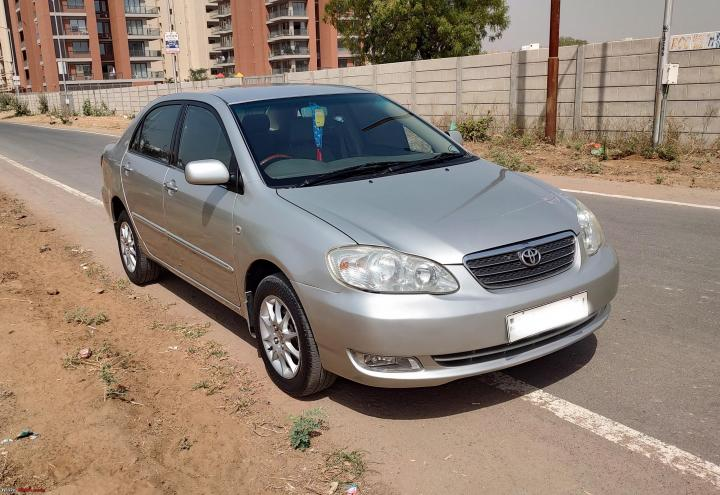

The resale value of a used car depends on multiple factors, such as its age, total distance traveled, engine capacity, and number of previous owners. Predicting the resale price is useful for car dealerships, buyers, and sellers to estimate a fair market value.
The objective of this experiment is to develop regression models that predict the resale price of used cars and evaluate their performance using MAE, MSE, RMSE, and R² Score.

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

print("Libraries imported successfully!")


Libraries imported successfully!


In [3]:

np.random.seed(42)

n = 500

age = np.random.randint(1, 16, n)
km_driven = np.random.randint(5000, 150001, n)
engine_cc = np.random.choice([800, 1000, 1200, 1500, 1800, 2000], n)
owners = np.random.randint(1, 4, n)

price = (
    900000
    - age * 35000
    - km_driven * 2.0
    + (engine_cc - 1000) * 250
    - (owners - 1) * 40000
    + np.random.normal(0, 45000, n)
)

price = np.maximum(price, 80000)

df = pd.DataFrame({
    "Car_Age": age,
    "Kilometers_Driven": km_driven,
    "Engine_CC": engine_cc,
    "Previous_Owners": owners,
    "Resale_Price": price
})

display(df.head())


,Car_Age,Kilometers_Driven,Engine_CC,Previous_Owners,Resale_Price
0,7,34592,800,2,433464.671108
1,4,15647,2000,3,963700.021267
2,13,144788,1000,1,80000.000000
3,15,115627,1000,3,80781.599064
4,11,75316,1800,2,519538.330198


In [4]:

print("Dataset Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())


Dataset Shape: (500, 5)

Missing Values:
Car_Age              0
Kilometers_Driven    0
Engine_CC            0
Previous_Owners      0
Resale_Price         0
dtype: int64

Statistical Summary:


,Car_Age,Kilometers_Driven,Engine_CC,Previous_Owners,Resale_Price
count,500.000000,500.000000,500.000000,500.000000,5.000000e+02
mean,7.846000,77290.588000,1369.600000,1.982000,5.258322e+05
std,4.367199,43074.269305,431.889914,0.811784,2.037868e+05
min,1.000000,5404.000000,800.000000,1.000000,8.000000e+04
25%,4.000000,38043.750000,1000.000000,1.000000,3.771279e+05
50%,8.000000,78687.000000,1200.000000,2.000000,5.257833e+05
75%,12.000000,114149.750000,1800.000000,3.000000,6.713784e+05
max,15.000000,149990.000000,2000.000000,3.000000,1.060418e+06


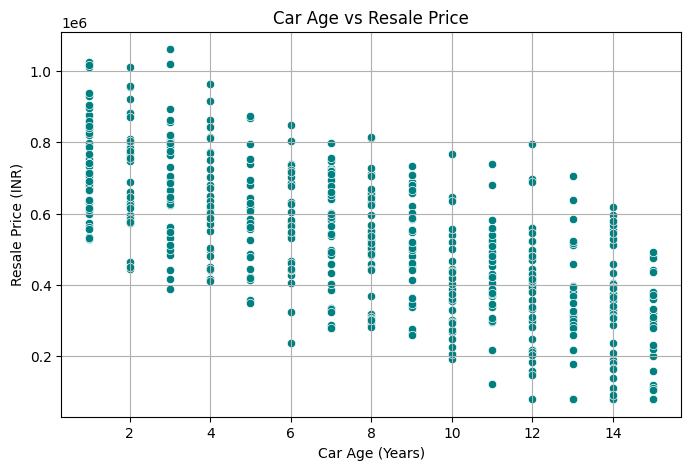

In [5]:

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Car_Age",
    y="Resale_Price",
    color="teal"
)

plt.title("Car Age vs Resale Price")
plt.xlabel("Car Age (Years)")
plt.ylabel("Resale Price (INR)")
plt.grid(True)
plt.show()


In [6]:

X = df[[
    "Car_Age",
    "Kilometers_Driven",
    "Engine_CC",
    "Previous_Owners"
]]

y = df["Resale_Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (400, 4)
Testing Data: (100, 4)


In [7]:

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    )
}

predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)

    print(name, "trained successfully!")


Linear Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!


We use four standard regression metrics to compare the models.<br>


In [8]:

results = []

for name, pred in predictions.items():

    mae = mean_absolute_error(y_test, pred)
    mse = mean_squared_error(y_test, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, pred)

    results.append([name, mae, mse, rmse, r2])

results_df = pd.DataFrame(
    results,
    columns=["Model", "MAE", "MSE", "RMSE", "R2 Score"]
)

display(results_df.round(2))


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,40468.30,2.403056e+09,49020.97,0.94
1,Decision Tree,70593.31,7.768792e+09,88140.75,0.79
2,Random Forest,49125.97,3.884105e+09,62322.59,0.90


In [9]:

results = []

for name, pred in predictions.items():

    mae = mean_absolute_error(y_test, pred)
    mse = mean_squared_error(y_test, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, pred)

    results.append([name, mae, mse, rmse, r2])

results_df = pd.DataFrame(
    results,
    columns=["Model", "MAE", "MSE", "RMSE", "R2 Score"]
)

display(results_df.round(2))


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,40468.30,2.403056e+09,49020.97,0.94
1,Decision Tree,70593.31,7.768792e+09,88140.75,0.79
2,Random Forest,49125.97,3.884105e+09,62322.59,0.90


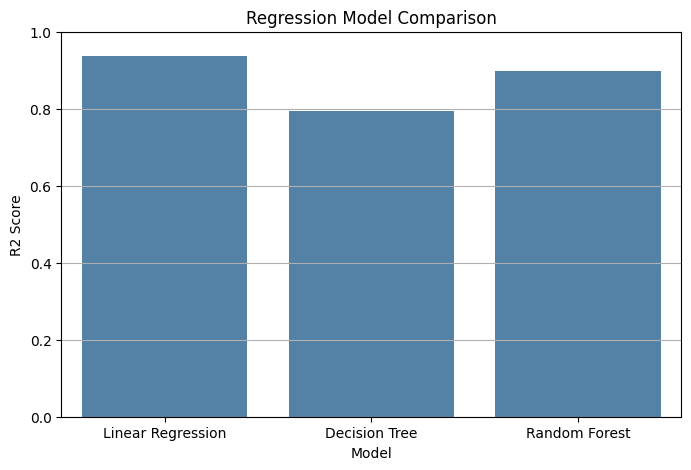

In [10]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="R2 Score",
    color="steelblue"
)

plt.title("Regression Model Comparison")
plt.ylabel("R2 Score")
plt.ylim(0, 1)
plt.grid(axis="y")
plt.show()


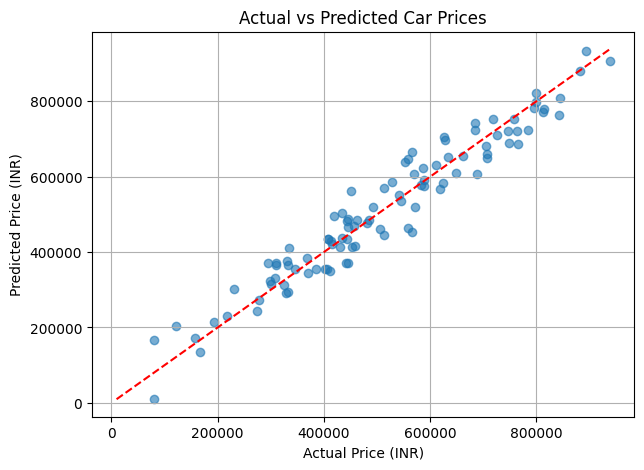

In [11]:

lr_pred = predictions["Linear Regression"]

plt.figure(figsize=(7, 5))
plt.scatter(y_test, lr_pred, alpha=0.6)

lower = min(y_test.min(), lr_pred.min())
upper = max(y_test.max(), lr_pred.max())

plt.plot([lower, upper], [lower, upper], "r--")

plt.xlabel("Actual Price (INR)")
plt.ylabel("Predicted Price (INR)")
plt.title("Actual vs Predicted Car Prices")
plt.grid(True)
plt.show()


In [12]:

best_model = results_df.loc[results_df["RMSE"].idxmin()]

print("Best Model:", best_model["Model"])
print("RMSE:", round(best_model["RMSE"], 2))
print("R2 Score:", round(best_model["R2 Score"], 4))


Best Model: Linear Regression
RMSE: 49020.97
R2 Score: 0.9363


**Conclusion**<br>
In this experiment, three regression models were developed to predict used car resale prices. Their performance was evaluated using MAE, MSE, RMSE, and R² Score. The model with the lowest RMSE provides the most accurate predictions for the given testing dataset.<br><br>
Because the simulated prices follow a largely linear relationship, Linear Regression is expected to perform well.

**Implement and Analyze Gradient Descent for Linear Regression**

**Problem Description**<br>
Gradient Descent is an optimization algorithm used to minimize the error of a Machine Learning model. In Linear Regression, it adjusts the weight and bias iteratively to find the best-fitting line.<br><br>
The objective of this experiment is to implement Gradient Descent manually to predict used car resale prices based on car age and analyze how the learning rate affects convergence.

In [13]:

X_gd = df[["Car_Age"]].values
y_gd = df["Resale_Price"].values

print("Input Shape:", X_gd.shape)
print("Output Shape:", y_gd.shape)


Input Shape: (500, 1)
Output Shape: (500,)


In [14]:

X_train_gd, X_test_gd, y_train_gd, y_test_gd = train_test_split(
    X_gd, y_gd, test_size=0.2, random_state=42
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_gd).flatten()
X_test_scaled = scaler.transform(X_test_gd).flatten()

print("Training and normalization completed!")


Training and normalization completed!


In [15]:

w = 0.0
b = 0.0

learning_rate = 0.1
epochs = 1000

cost_history = []

print("Initial Weight:", w)
print("Initial Bias:", b)
print("Learning Rate:", learning_rate)
print("Epochs:", epochs)


Initial Weight: 0.0
Initial Bias: 0.0
Learning Rate: 0.1
Epochs: 1000


In [16]:

m = len(X_train_scaled)

for epoch in range(epochs):

    predictions_gd = w * X_train_scaled + b

    error = predictions_gd - y_train_gd

    dw = (2 / m) * np.sum(error * X_train_scaled)
    db = (2 / m) * np.sum(error)

    w = w - learning_rate * dw
    b = b - learning_rate * db

    updated_predictions = w * X_train_scaled + b

    cost = np.mean(
        (updated_predictions - y_train_gd) ** 2
    )

    cost_history.append(cost)

    if epoch % 100 == 0:
        print(f"Epoch {epoch}: Cost = {cost:.2f}")

print("\nFinal Weight:", w)
print("Final Bias:", b)


Epoch 0: Cost = 214087090239.30
Epoch 100: Cost = 21171278902.98
Epoch 200: Cost = 21171278902.98
Epoch 300: Cost = 21171278902.98
Epoch 400: Cost = 21171278902.98
Epoch 500: Cost = 21171278902.98
Epoch 600: Cost = 21171278902.98
Epoch 700: Cost = 21171278902.98
Epoch 800: Cost = 21171278902.98
Epoch 900: Cost = 21171278902.98

Final Weight: -145409.11659359327
Final Bias: 529421.5182862052


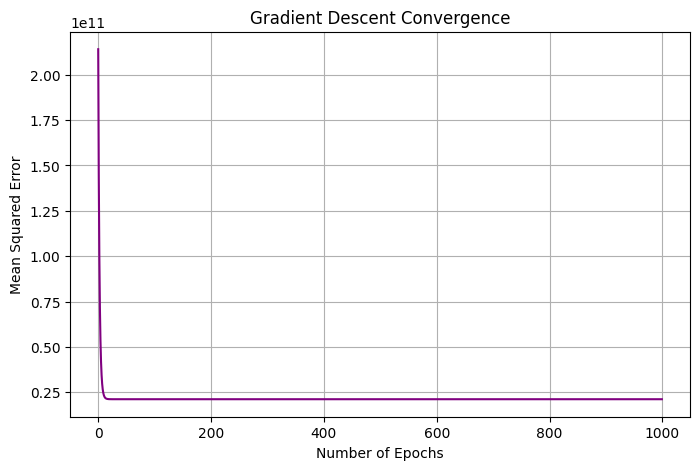

In [17]:

plt.figure(figsize=(8, 5))

plt.plot(cost_history, color="purple")

plt.title("Gradient Descent Convergence")
plt.xlabel("Number of Epochs")
plt.ylabel("Mean Squared Error")
plt.grid(True)

plt.show()


In [18]:

y_pred_gd = w * X_test_scaled + b

comparison = pd.DataFrame({
    "Actual Price": y_test_gd[:10],
    "Predicted Price": y_pred_gd[:10]
})

display(comparison.round(2))


,Actual Price,Predicted Price
0,368483.12,428182.67
1,688545.77,395498.62
2,415415.07,656971.03
3,588025.17,493550.77
4,434153.21,330130.51
5,557702.60,689655.08
6,624936.33,526234.82
7,408503.33,395498.62
8,481337.02,493550.77
9,462722.84,493550.77


In [19]:

mae_gd = mean_absolute_error(y_test_gd, y_pred_gd)
mse_gd = mean_squared_error(y_test_gd, y_pred_gd)
rmse_gd = np.sqrt(mse_gd)
r2_gd = r2_score(y_test_gd, y_pred_gd)

print("Gradient Descent Performance")
print("-----------------------------")
print("MAE:", round(mae_gd, 2))
print("MSE:", round(mse_gd, 2))
print("RMSE:", round(rmse_gd, 2))
print("R2 Score:", round(r2_gd, 4))


Gradient Descent Performance
-----------------------------
MAE: 123389.1
MSE: 23174380766.11
RMSE: 152231.34
R2 Score: 0.3855


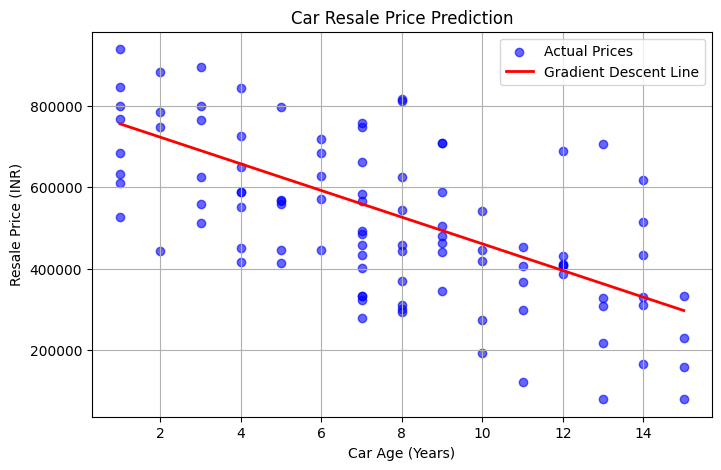

In [20]:

plt.figure(figsize=(8, 5))

plt.scatter(
    X_test_gd.flatten(),
    y_test_gd,
    color="blue",
    label="Actual Prices",
    alpha=0.6
)

order = np.argsort(X_test_gd.flatten())

plt.plot(
    X_test_gd.flatten()[order],
    y_pred_gd[order],
    color="red",
    linewidth=2,
    label="Gradient Descent Line"
)

plt.xlabel("Car Age (Years)")
plt.ylabel("Resale Price (INR)")
plt.title("Car Resale Price Prediction")
plt.legend()
plt.grid(True)

plt.show()


In [21]:

sk_model = LinearRegression()

sk_model.fit(
    X_train_scaled.reshape(-1, 1),
    y_train_gd
)

y_pred_sk = sk_model.predict(
    X_test_scaled.reshape(-1, 1)
)

comparison_df = pd.DataFrame({
    "Model": [
        "Manual Gradient Descent",
        "Scikit-learn Linear Regression"
    ],
    "RMSE": [
        rmse_gd,
        np.sqrt(mean_squared_error(y_test_gd, y_pred_sk))
    ],
    "R2 Score": [
        r2_gd,
        r2_score(y_test_gd, y_pred_sk)
    ]
})

display(comparison_df.round(4))


,Model,RMSE,R2 Score
0,Manual Gradient Descent,152231.3396,0.3855
1,Scikit-learn Linear Regression,152231.3396,0.3855


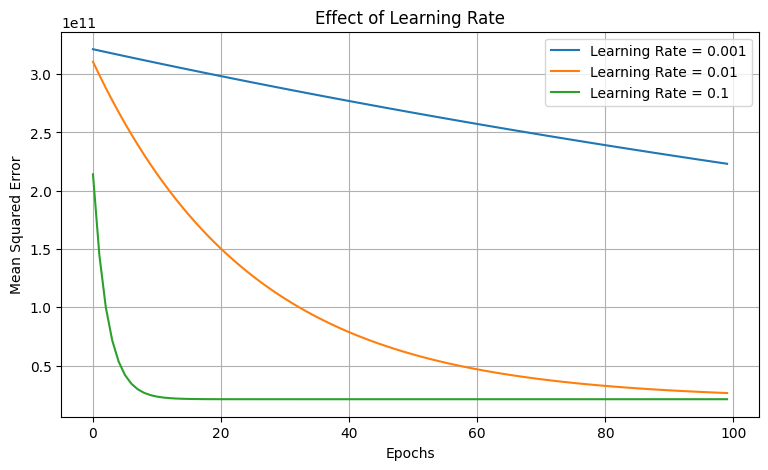

In [22]:

learning_rates = [0.001, 0.01, 0.1]

plt.figure(figsize=(9, 5))

for lr in learning_rates:

    weight = 0.0
    bias = 0.0
    costs = []

    for epoch in range(100):

        prediction = weight * X_train_scaled + bias
        error = prediction - y_train_gd

        dw = (2 / m) * np.sum(error * X_train_scaled)
        db = (2 / m) * np.sum(error)

        weight -= lr * dw
        bias -= lr * db

        cost = np.mean(
            (weight * X_train_scaled + bias - y_train_gd) ** 2
        )

        costs.append(cost)

    plt.plot(costs, label=f"Learning Rate = {lr}")

plt.title("Effect of Learning Rate")
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True)

plt.show()


**Conclusion**<br>
In this experiment, Gradient Descent was implemented manually for Linear Regression to predict used car resale prices based on vehicle age. The cost function decreased over successive iterations, demonstrating the optimization process.<br><br>
The model's performance was evaluated using MAE, MSE, RMSE, and R² Score. Different learning rates were compared to understand their effect on convergence.<br><br>
The manual implementation was also compared with Scikit-learn Linear Regression, demonstrating that Gradient Descent can successfully optimize a linear regression model.